In [1]:
import pandas as pd
import numpy as np
import sys

sys.path.append("../src")

import clean
import features

data_folder = "../data/cleaned/"

names = ["orders", "order_items", "customers", "restaurants", "menu",
         "delivery_partners", "payments", "customer_feedback",
         "promotions", "cities", "traffic", "weather"]

tables = {}
clean_tables = {}

for n in names:
    tables[n] = pd.read_csv(data_folder + n + ".csv")
    clean_tables[n] = getattr(clean, "clean_" + n)(tables[n])

abt = clean.build_abt(clean_tables)
abt = features.build_features(abt)

print("ABT shape:", abt.shape)

ABT shape: (20475, 68)


In [2]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
%pip install scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = abt.dropna(subset=['DeliveryTimeMinutes'])
df = df[df['DeliveryTimeMinutes'] <= 100]
print("Rows kept:", df.shape[0], "of", abt.shape[0])

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

baseline = train_df['DeliveryTimeMinutes'].mean()
y_test = test_df['DeliveryTimeMinutes']
pred = [baseline] * len(y_test)

print("Baseline (average time):", round(baseline, 1), "minutes")
print("MAE :", round(mean_absolute_error(y_test, pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 2))
print("R2  :", round(r2_score(y_test, pred), 3))

Rows kept: 20325 of 20475
Baseline (average time): 36.7 minutes
MAE : 10.22
RMSE: 13.72
R2  : -0.0


In [5]:
print(abt.columns[57:].tolist())
print()

cat_cols = ['PaymentMethod', 'CustomerGender', 'Membership', 'Cuisine',
            'RestaurantType', 'VehicleType', 'Region', 'MealTime',
            'DayOfWeek', 'RestaurantCity', 'Area', 'PreferredCuisine']

for c in cat_cols:
    print(c, "->", abt[c].nunique(), "unique values,", abt[c].isna().sum(), "missing")

['OrderHour', 'PeakHour', 'DayOfWeek', 'WeekendOrder', 'OrderMonth', 'MealTime', 'CustomerTenure', 'PartnerExperienceDays', 'HasCoupon', 'DiscountPercent', 'DeliveryEfficiency']

PaymentMethod -> 6 unique values, 0 missing
CustomerGender -> 3 unique values, 223 missing
Membership -> 3 unique values, 195 missing
Cuisine -> 19 unique values, 232 missing
RestaurantType -> 5 unique values, 0 missing
VehicleType -> 4 unique values, 0 missing
Region -> 4 unique values, 0 missing
MealTime -> 5 unique values, 0 missing
DayOfWeek -> 7 unique values, 0 missing
RestaurantCity -> 25 unique values, 0 missing
Area -> 12 unique values, 0 missing
PreferredCuisine -> 14 unique values, 381 missing


In [6]:
print(abt[['DeliveryEfficiency', 'DeliveryTimeMinutes']].head(5))
print()
print(abt[['DeliveryEfficiency', 'DeliveryTimeMinutes']].corr().round(3))
print()
print(abt[['PeakHour', 'WeekendOrder', 'HasCoupon', 'CustomerTenure', 'PartnerExperienceDays']].dtypes)

   DeliveryEfficiency  DeliveryTimeMinutes
0                1.10                 43.0
1                2.65                 18.0
2                0.59                 50.0
3                1.21                 29.0
4                2.10                 25.0

                     DeliveryEfficiency  DeliveryTimeMinutes
DeliveryEfficiency                1.000               -0.664
DeliveryTimeMinutes              -0.664                1.000

PeakHour                   int64
WeekendOrder               int64
HasCoupon                  int64
CustomerTenure           float64
PartnerExperienceDays    float64
dtype: object


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

num_features = ['FoodCost', 'DeliveryFee', 'DiscountPercentage', 'CustomerAge', 'TotalOrders',
                'RestaurantRating', 'AverageCost', 'Latitude', 'Longitude', 'PartnerAge',
                'PartnerRating', 'CompletedDeliveries', 'PartnerAvgDeliveryTime', 'ItemCount',
                'Temperature', 'Rainfall', 'Humidity', 'AverageSpeed', 'CityPopulation',
                'CityAverageIncome', 'OrderHour', 'PeakHour', 'WeekendOrder', 'HasCoupon',
                'CustomerTenure', 'PartnerExperienceDays']

cat_features = ['PaymentMethod', 'CustomerGender', 'Membership', 'Cuisine', 'RestaurantType',
                'VehicleType', 'Region', 'MealTime', 'DayOfWeek', 'RestaurantCity', 'Area']

X_train = train_df[num_features + cat_features]
y_train = train_df['DeliveryTimeMinutes']
X_test = test_df[num_features + cat_features]
y_test = test_df['DeliveryTimeMinutes']

num_prep = SimpleImputer(strategy='median')
cat_prep = Pipeline([
    ('fill', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_prep, num_features),
    ('cat', cat_prep, cat_features)
])

X_train_ready = preprocessor.fit_transform(X_train)
X_test_ready = preprocessor.transform(X_test)

print("Train shape:", X_train_ready.shape)
print("Test shape :", X_test_ready.shape)

Train shape: (16260, 119)
Test shape : (4065, 119)


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42)
}

results = []

baseline_pred = [y_train.mean()] * len(y_test)
results.append(['Baseline (average)',
                mean_absolute_error(y_test, baseline_pred),
                np.sqrt(mean_squared_error(y_test, baseline_pred)),
                r2_score(y_test, baseline_pred),
                0.0])

for name, model in models.items():
    model.fit(X_train_ready, y_train)
    test_pred = model.predict(X_test_ready)
    train_pred = model.predict(X_train_ready)
    results.append([name,
                    mean_absolute_error(y_test, test_pred),
                    np.sqrt(mean_squared_error(y_test, test_pred)),
                    r2_score(y_test, test_pred),
                    r2_score(y_train, train_pred)])

results_df = pd.DataFrame(results, columns=['Model', 'MAE', 'RMSE', 'R2_test', 'R2_train'])
print(results_df.round(3))

                Model     MAE    RMSE  R2_test  R2_train
0  Baseline (average)  10.224  13.717   -0.000     0.000
1   Linear Regression  10.224  13.715    0.000     0.001
2       Decision Tree  10.300  13.808   -0.013     0.014
3       Random Forest  10.252  13.747   -0.004     0.147
4   Gradient Boosting  10.268  13.751   -0.005     0.049


In [9]:
from sklearn.model_selection import RandomizedSearchCV

gb_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [2, 3, 4],
    'learning_rate': [0.01, 0.05, 0.1],
    'min_samples_leaf': [20, 50, 100]
}

rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 8],
    'min_samples_leaf': [20, 50, 100]
}

tuned = {}

for name, model, params in [
    ('Gradient Boosting (tuned)', GradientBoostingRegressor(random_state=42), gb_params),
    ('Random Forest (tuned)', RandomForestRegressor(random_state=42, n_jobs=-1), rf_params)
]:
    search = RandomizedSearchCV(model, params, n_iter=8, cv=3,
                                scoring='neg_mean_absolute_error',
                                random_state=42)
    search.fit(X_train_ready, y_train)
    pred = search.predict(X_test_ready)
    print(name)
    print("  Best settings:", search.best_params_)
    print("  Test MAE :", round(mean_absolute_error(y_test, pred), 3))
    print("  Test RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
    print("  Test R2  :", round(r2_score(y_test, pred), 4))
    tuned[name] = search

Gradient Boosting (tuned)
  Best settings: {'n_estimators': 50, 'min_samples_leaf': 20, 'max_depth': 2, 'learning_rate': 0.01}
  Test MAE : 10.227
  Test RMSE: 13.718
  Test R2  : -0.0002
Random Forest (tuned)
  Best settings: {'n_estimators': 200, 'min_samples_leaf': 100, 'max_depth': 3}
  Test MAE : 10.225
  Test RMSE: 13.717
  Test R2  : 0.0001


                       Model     MAE    RMSE  R2_test  R2_train
1          Linear Regression  10.224  13.715    0.000     0.001
0         Baseline (average)  10.224  13.717   -0.000     0.000
6      Random Forest (tuned)  10.225  13.717    0.000     0.006
5  Gradient Boosting (tuned)  10.227  13.718   -0.000     0.001
3              Random Forest  10.252  13.747   -0.004     0.147
4          Gradient Boosting  10.268  13.751   -0.005     0.049
2              Decision Tree  10.300  13.808   -0.013     0.014


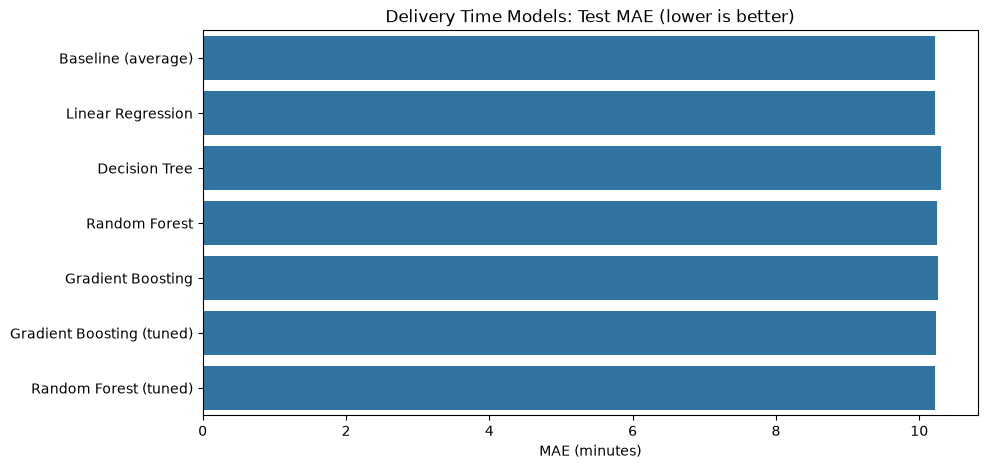

In [10]:
tuned_rows = []
for name, search in tuned.items():
    test_pred = search.predict(X_test_ready)
    train_pred = search.predict(X_train_ready)
    tuned_rows.append([name,
                       mean_absolute_error(y_test, test_pred),
                       np.sqrt(mean_squared_error(y_test, test_pred)),
                       r2_score(y_test, test_pred),
                       r2_score(y_train, train_pred)])

final_df = pd.concat([results_df, pd.DataFrame(tuned_rows, columns=results_df.columns)],
                     ignore_index=True)
print(final_df.sort_values('MAE').round(3))

final_df.to_csv('../reports/delivery_model_comparison.csv', index=False)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.barplot(x=final_df['MAE'], y=final_df['Model'])
plt.title('Delivery Time Models: Test MAE (lower is better)')
plt.xlabel('MAE (minutes)')
plt.ylabel('')
plt.show()

MAE : 10.224
RMSE: 13.715
R2  : 0.0003

Predictions summary:
count    4065.00
mean       36.72
std         0.52
min        34.68
25%        36.38
50%        36.71
75%        37.06
max        38.87
dtype: float64


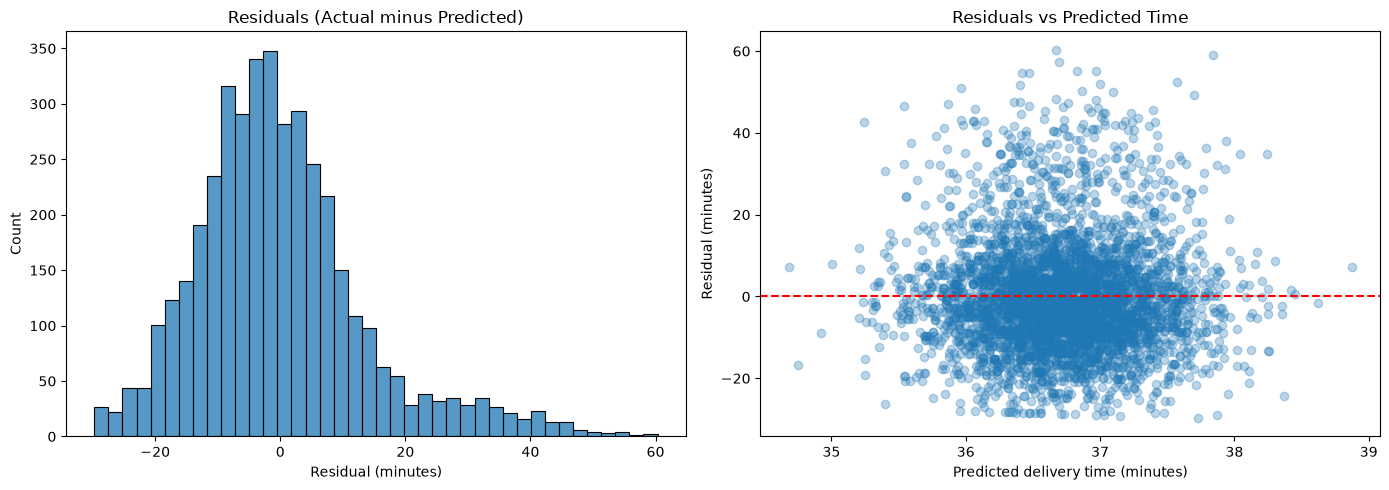

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

final_delivery = Pipeline([
    ('prep', preprocessor),
    ('model', LinearRegression())
])
final_delivery.fit(X_train, y_train)

test_pred = final_delivery.predict(X_test)
residuals = y_test - test_pred

print("MAE :", round(mean_absolute_error(y_test, test_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, test_pred)), 3))
print("R2  :", round(r2_score(y_test, test_pred), 4))
print()
print("Predictions summary:")
print(pd.Series(test_pred).describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(residuals, bins=40, ax=axes[0])
axes[0].set_title('Residuals (Actual minus Predicted)')
axes[0].set_xlabel('Residual (minutes)')

axes[1].scatter(test_pred, residuals, alpha=0.3)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Residuals vs Predicted Time')
axes[1].set_xlabel('Predicted delivery time (minutes)')
axes[1].set_ylabel('Residual (minutes)')

plt.tight_layout()
plt.show()

Average residual by order status:
                    count  mean
OrderStatus                    
Cancelled             900  -2.9
Delivered            2304  -3.3
Delivered Late        413  27.3
Food Not Delivered    448  -2.4

Top 10 columns by importance:
CityPopulation            0.0064
CompletedDeliveries       0.0016
Rainfall                  0.0013
DeliveryFee               0.0012
Humidity                  0.0005
PartnerAvgDeliveryTime    0.0004
CustomerTenure            0.0004
PartnerExperienceDays     0.0001
PartnerAge                0.0001
MealTime                  0.0000
dtype: float64


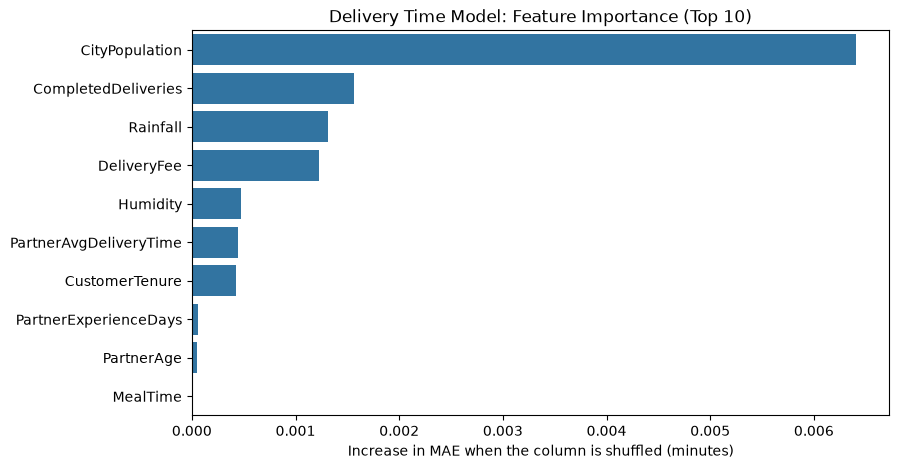

Model saved to models/delivery_time_best_model.pkl


In [12]:
from sklearn.inspection import permutation_importance
import joblib

check = test_df[['OrderStatus']].copy()
check['Residual'] = residuals
print("Average residual by order status:")
print(check.groupby('OrderStatus')['Residual'].agg(['count', 'mean']).round(1))
print()

perm = permutation_importance(final_delivery, X_test, y_test, n_repeats=5,
                              random_state=42, scoring='neg_mean_absolute_error')
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
print("Top 10 columns by importance:")
print(imp.head(10).round(4))

plt.figure(figsize=(9, 5))
sns.barplot(x=imp.head(10).values, y=imp.head(10).index)
plt.title('Delivery Time Model: Feature Importance (Top 10)')
plt.xlabel('Increase in MAE when the column is shuffled (minutes)')
plt.ylabel('')
plt.show()

joblib.dump(final_delivery, '../models/delivery_time_best_model.pkl')
print("Model saved to models/delivery_time_best_model.pkl")

In [13]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

OUT = '../powerbi/data/'
os.makedirs(OUT, exist_ok=True)

pred = final_delivery.predict(X_test)

out = pd.DataFrame({'Actual': np.array(y_test), 'Predicted': np.array(pred)})
out['Residual'] = out['Actual'] - out['Predicted']
out.to_csv(OUT + 'delivery_predictions.csv', index=False)

imp_df = imp.reset_index()
imp_df.columns = ['Feature', 'Importance']
imp_df.to_csv(OUT + 'delivery_feature_importance.csv', index=False)

mse = mean_squared_error(y_test, pred)
metrics = pd.DataFrame({'Metric': ['MAE', 'RMSE', 'R2'],
                        'Value': [mean_absolute_error(y_test, pred), np.sqrt(mse), r2_score(y_test, pred)]})
metrics.to_csv(OUT + 'delivery_metrics.csv', index=False)

print(out.shape)
print(metrics.round(4))
print(os.listdir(OUT))

(4065, 3)
  Metric    Value
0    MAE  10.2240
1   RMSE  13.7151
2     R2   0.0003
['churn_drivers.csv', 'churn_metrics.csv', 'churn_scores.csv', 'delivery_feature_importance.csv', 'delivery_metrics.csv', 'delivery_predictions.csv']


In [14]:
import pandas as pd

d = pd.read_csv('../powerbi/data/delivery_predictions.csv')
d['RowID'] = range(1, len(d) + 1)
d.to_csv('../powerbi/data/delivery_predictions.csv', index=False)
print(d.shape)

(4065, 4)
